In [1]:
from MITgcmutils import mds
from matplotlib import pyplot as plt
import numpy as np
import os
import sys
import cmocean
import fileinput

In [217]:
bathy_iceplume = np.fromfile("experiments/plume_base/input/bathymetry.bin", dtype="<f8")  # try big-endian double
plumeMask_iceplume = np.fromfile("experiments/plume_base/input/plumeMask.bin", dtype="<f8")  # try big-endian double

bathy_iceplume = bathy_iceplume.reshape(12, 120)
plumeMask_iceplume = plumeMask_iceplume.reshape(12, 120)

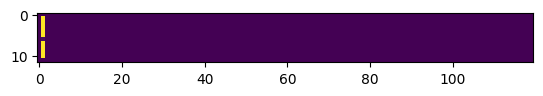

In [218]:
plumeMask_iceplume
plt.imshow(plumeMask_iceplume)

In [223]:
plumeMask_iceplume[:,1]

array([0.00000e+000, 3.03865e-319, 3.03865e-319, 3.03865e-319,
       3.03865e-319, 3.03865e-319, 1.04347e-320, 3.03865e-319,
       3.03865e-319, 3.03865e-319, 3.03865e-319, 0.00000e+000])

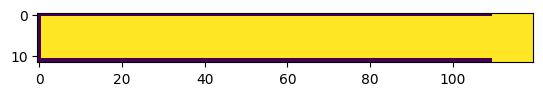

In [219]:
plt.imshow(bathy_iceplume)

In [212]:
dir = 'experiments/doubleplume_base/run/%s'
name = ["W", "T", "S", "icefrntW", "icefrntR", "icefrntS", "icefrntT", "U"]
i = 4
T_ocean = mds.rdmds(dir%(name[1]), i)


OSError: No files found for experiments/doubleplume_base/run/T.0000000004.meta

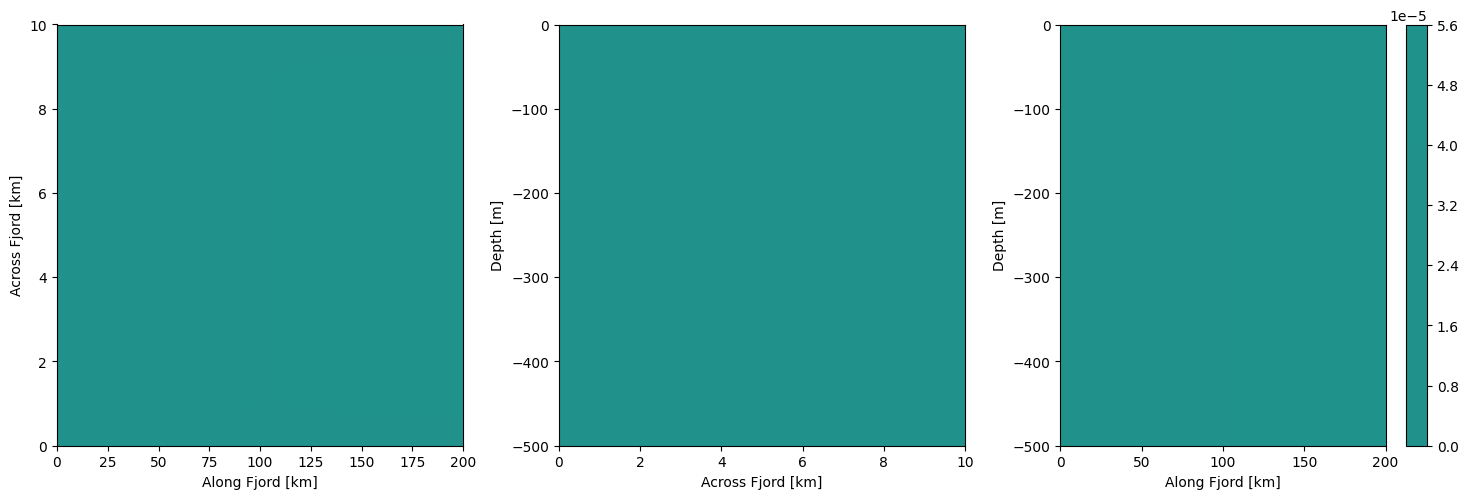

In [ ]:
fname = "experiments/doubleplume_base/run/"
i = 4
T_ocean = np.fromfile(fname + "W." + f"{i:010d}" + ".001.001.data", dtype="<f4")  # try big-endian double
T_ocean = T_ocean.reshape((50,11,50),)
X = np.linspace(0,200,50)
Y = np.linspace(0,10,11)
Z = np.linspace(-500,0,50)

fig, ax = plt.subplots(1, 3, figsize = (15,5))
ax[0].contourf(X, Y, T_ocean[1,:,:], vmin = -0.005, vmax = 0.005) # z is first index, y is second, x is third
ax[1].contourf(Y, Z, T_ocean[:,:,2], vmin = -0.005, vmax = 0.005)
c = ax[2].contourf(X, Z, T_ocean[:,8,:], vmin = -0.005, vmax = 0.005)

ax[0].set_xlabel('Along Fjord [km]'); ax[0].set_ylabel('Across Fjord [km]')
ax[1].set_xlabel('Across Fjord [km]'); ax[1].set_ylabel('Depth [m]')
ax[2].set_xlabel('Along Fjord [km]'); ax[2].set_ylabel('Depth [m]')
plt.tight_layout()
plt.colorbar(c)


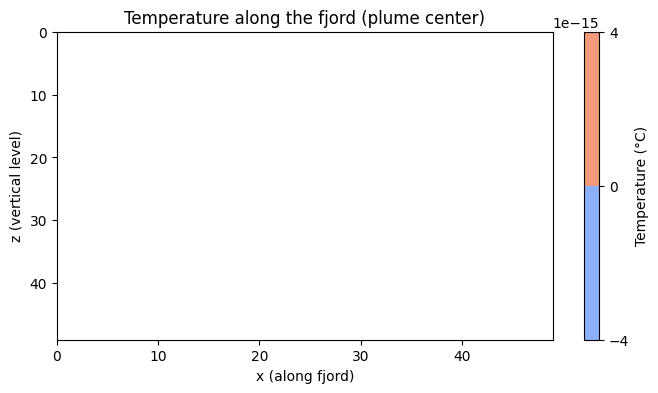

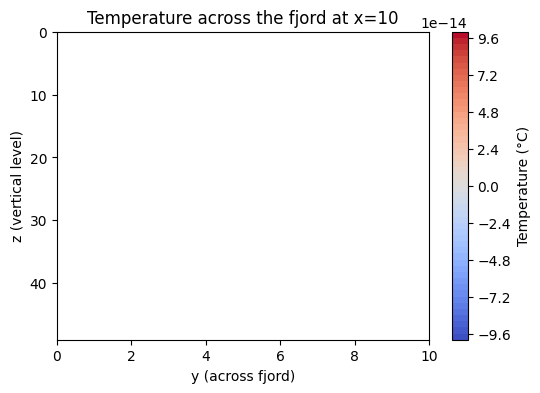

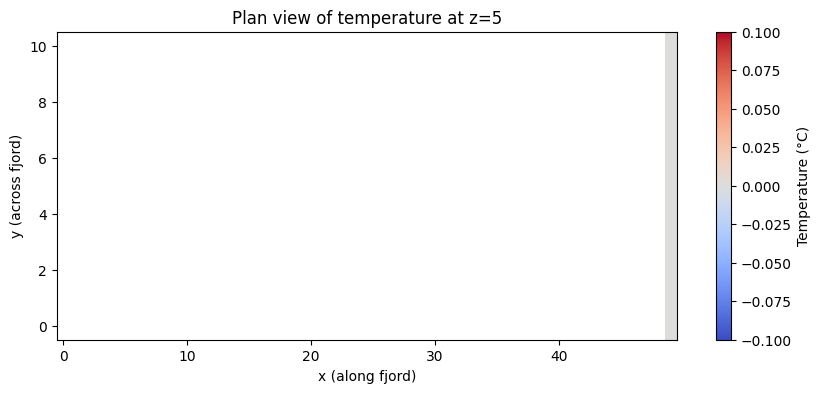

In [524]:
# MITgcm usually writes T in Fortran order: (x, y, z)
Nx = 50
Ny = 11
Nz = 50
i = 200
T = np.fromfile(fname + "W." + f"{i:010d}" + ".001.001.data", dtype="<f4")
T = T.reshape((Nx, Ny, Nz), order="F")
colormap = 'coolwarm'
# ---------------------------
# Plot along the fjord (x vs z at plume center y=mp)
# ---------------------------
plt.figure(figsize=(8,4))
plt.contourf(np.arange(Nx), np.arange(Nz), T[:, mp, :].T, levels=50, cmap=colormap)
plt.gca().invert_yaxis()  # depth increases downward
plt.xlabel("x (along fjord)")
plt.ylabel("z (vertical level)")
plt.title("Temperature along the fjord (plume center)")
plt.colorbar(label="Temperature (°C)")
plt.show()

# ---------------------------
# Plot across the fjord (y vs z at a given x, e.g., x=10)
# ---------------------------
x_index = 10
plt.figure(figsize=(6,4))
plt.contourf(np.arange(Ny), np.arange(Nz), T[x_index, :, :].T, levels=50, cmap=colormap)
plt.gca().invert_yaxis()
plt.xlabel("y (across fjord)")
plt.ylabel("z (vertical level)")
plt.title(f"Temperature across the fjord at x={x_index}")
plt.colorbar(label="Temperature (°C)")
plt.show()

# ---------------------------
# Plan view (x vs y at a given z level, e.g., near surface z=5)
# ---------------------------
z_index = 5
plt.figure(figsize=(10,4))
plt.imshow(T[:, :, z_index].T, origin='lower', aspect='auto', cmap=colormap)
plt.xlabel("x (along fjord)")
plt.ylabel("y (across fjord)")
plt.title(f"Plan view of temperature at z={z_index}")
plt.colorbar(label="Temperature (°C)")
plt.show()

In [530]:
fname = "experiments/doubleplume_base/run/"
i = 32
T_ocean = np.fromfile(fname + "W." + f"{i:010d}" + ".001.001.data", dtype="<f4")  # try big-endian double
T_ocean = T_ocean.reshape((50,11,50),)
X = np.linspace(0,200,50)
Y = np.linspace(0,10,11)
Z = np.linspace(-500,0,50)

fig, ax = plt.subplots(1, 3, figsize = (15,5))
ax[0].contourf(X, Y, T_ocean[1,:,:]) # z is first index, y is second, x is third
ax[1].contourf(Y, Z, T_ocean[:,:,2])
c = ax[2].contourf(X, Z, T_ocean[:,8,:])

ax[0].set_xlabel('Along Fjord [km]'); ax[0].set_ylabel('Across Fjord [km]')
ax[1].set_xlabel('Across Fjord [km]'); ax[1].set_ylabel('Depth [m]')
ax[2].set_xlabel('Along Fjord [km]'); ax[2].set_ylabel('Depth [m]')
plt.tight_layout()
plt.colorbar(c)

FileNotFoundError: [Errno 2] No such file or directory: 'experiments/doubleplume_base/run/W.0000000032.001.001.data'

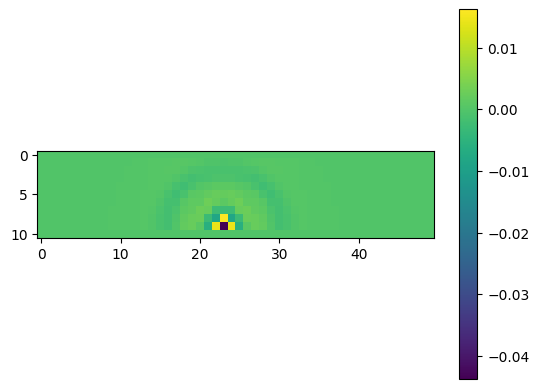

In [528]:
plt.imshow(T_ocean[2,:,:][::-1])
plt.colorbar()

In [9]:
dynName = ['plumeDiag', 'plumeDiag', 'plumeDiag', 'plumeDiag','plumeDiag']
name = ["W", "T", "S", "icefrntW", "icefrntR", "icefrntS", "icefrntT", "U"]
units = ["[m/s]", "[C]", "[PSU]", "[m/day]", "[m/day]"]
k = 4
i = 40
dir = 'experiments/doubleplume_base/run/%s'
Qi = mds.rdmds(dir%(name[4]), i)#, dtype = ">f4")
#Mi = mds.rdmds(dir%(name[3]), i, )
Hi = mds.rdmds(dir%(name[6]), i)
Bi = mds.rdmds(dir%(name[5]), i)

Qi = Qi[np.where(Qi != 0)][::-1]
# Mi = Mi[np.where(Mi != 0)][::-1]
Hi = Hi[np.where(Hi != 0)][::-1]
Bi = Bi[np.where(Bi != 0)][::-1]
plt.plot(Qi)
# plt.colorbar()

OSError: No files found for experiments/doubleplume_base/run/icefrntR.0000000040.meta

In [10]:
def readPlumeData(filePath, i):
    Mi = np.fromfile(filePath + "icefrntW." + f"{i:010d}" + ".001.001.data", dtype="<f4")  # try big-endian double
    Mi = Mi[np.where(Mi !=0)]
    Mi = Mi[~np.isnan(Mi)]

    Qi = np.fromfile(filePath + "icefrntR." + f"{i:010d}" + ".001.001.data", dtype="<f4")  # try big-endian double
    Qi = Qi[np.where(Qi !=0)]
    Qi = Qi[~np.isnan(Qi)]

    Hi = np.fromfile(filePath + "icefrntT." + f"{i:010d}" + ".001.001.data", dtype="<f4")  # try big-endian double
    Hi = Hi[np.where(Hi !=0)]
    Hi = Hi[~np.isnan(Hi)]

    Bi = np.fromfile(filePath + "icefrntS." + f"{i:010d}" + ".001.001.data", dtype="<f4")  # try big-endian double
    Bi = Bi[np.where(Bi !=0)]
    Bi = Bi[~np.isnan(Bi)]

    Hg = np.fromfile(filePath + "icefrntHg." + f"{i:010d}" + ".001.001.data", dtype="<f4")  # try big-endian double
    Hg = Hg[np.where(Hg !=0)]
    Hg = Hg[~np.isnan(Hg)]

    Mb = np.fromfile(filePath + "icefrntMb." + f"{i:010d}" + ".001.001.data", dtype="<f4")  # try big-endian double
    Mb = Mb[np.where(Mb !=0)]
    Mb = Mb[~np.isnan(Mb)]

    Ci = np.fromfile(filePath + "icefrntC." + f"{i:010d}" + ".001.001.data", dtype="<f4")  # try big-endian double
    Ci = Ci[np.where(Ci !=0)]
    Ci = Ci[~np.isnan(Ci)]

    return Mi, Qi, Hi, Bi, Hg, Mb, Ci


In [13]:
# we are little endian, but mds is trying to read as big endian

fname = "experiments/doubleplume_base/run/"
Mi, Qi, Hi, Bi, Hg, Mb, Ci = readPlumeData(fname, 4)

fig, ax = plt.subplots(1,4, figsize = (20,5))
z = np.linspace(-500,0,len(Qi))
ax[0].plot(Qi/(np.pi * Mi)**(1/2), z[::-1])
ax[1].plot(Mi/Qi,z[::-1])
ax[2].plot(Hi[1:]/(4185 * 1025* Qi[1:]) - 273.15,z[1:][::-1])
ax[3].plot(Bi[1:]/Qi[1:],z[1:][::-1])


FileNotFoundError: [Errno 2] No such file or directory: 'experiments/doubleplume_base/run/icefrntHg.0000000004.001.001.data'

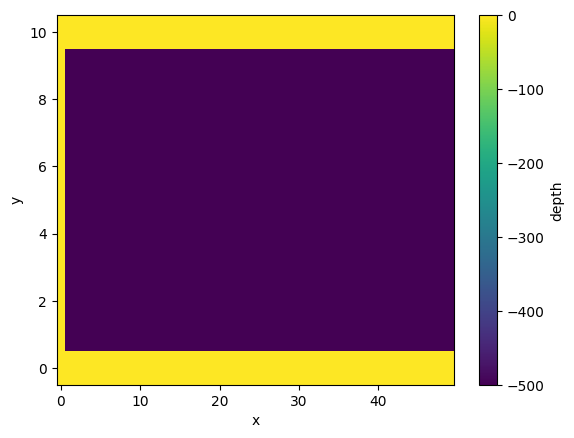

In [392]:
fname = "experiments/doubleplume_base/input/bathymetry.bin"
bathy = np.fromfile(fname, dtype="<f8") ## In little endian
bathy = bathy.reshape((50,11), order = 'F') ## Do it backwards y, x or put fortran order
plt.imshow(bathy.T, origin="lower", aspect="auto")
plt.xlabel("x")
plt.ylabel("y")
plt.colorbar(label="depth")


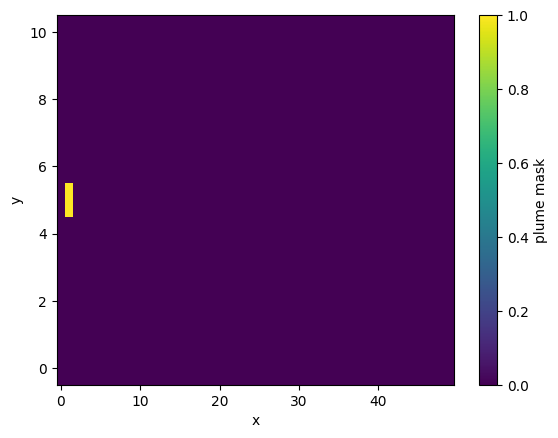

In [ ]:
Nx = 50
Ny = 11

fname = "experiments/doubleplume_base/input/plumemask.bin"

# Construct from scratch
T = np.zeros((Ny, Nx), dtype=">f8")

mp = Ny // 2

# Ice face MUST be i = 0
T[1,25] = 1.0

# Plot (transpose ONLY for plotting)
plt.imshow(T, origin="lower", aspect="auto")
plt.xlabel("x")
plt.ylabel("y")
plt.colorbar(label="plume mask")

# Write Fortran order
T.T.tofile(fname)



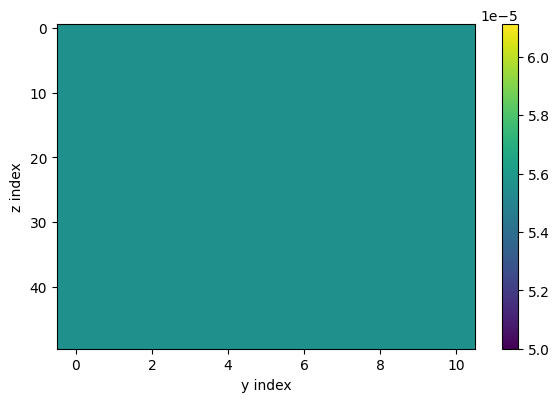

In [ ]:
fname = "experiments/doubleplume_base/input/EBCu.bin"

data = np.fromfile(fname, dtype="<f8")
Nz = 50
expected_size = Ny * Nz
if data.size != expected_size:
    raise ValueError(
        f"{fname}: expected {expected_size} values, got {data.size}"
    )

# MITgcm uses Fortran ordering
field = data.reshape((Ny, Nz), order="F")

plt.figure(figsize=(6,4))
plt.imshow(
    field.T,
    origin="upper",
    aspect="auto",
)
plt.xlabel("y index")
plt.ylabel("z index")
plt.tight_layout()
plt.colorbar()


In [451]:
fname = "experiments/doubleplume_base/input/dely.bin"

data = np.fromfile(fname, dtype="<f8")
Nz = 50
expected_size = Ny
if data.size != expected_size:
    raise ValueError(
        f"{fname}: expected {expected_size} values, got {data.size}"
    )

data

array([200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200.])

In [450]:
field.T

array([[5.55555556e-05, 5.55555556e-05, 5.55555556e-05, 5.55555556e-05,
        5.55555556e-05, 5.55555556e-05, 5.55555556e-05, 5.55555556e-05,
        5.55555556e-05, 5.55555556e-05, 5.55555556e-05],
       [5.55555556e-05, 5.55555556e-05, 5.55555556e-05, 5.55555556e-05,
        5.55555556e-05, 5.55555556e-05, 5.55555556e-05, 5.55555556e-05,
        5.55555556e-05, 5.55555556e-05, 5.55555556e-05],
       [5.55555556e-05, 5.55555556e-05, 5.55555556e-05, 5.55555556e-05,
        5.55555556e-05, 5.55555556e-05, 5.55555556e-05, 5.55555556e-05,
        5.55555556e-05, 5.55555556e-05, 5.55555556e-05],
       [5.55555556e-05, 5.55555556e-05, 5.55555556e-05, 5.55555556e-05,
        5.55555556e-05, 5.55555556e-05, 5.55555556e-05, 5.55555556e-05,
        5.55555556e-05, 5.55555556e-05, 5.55555556e-05],
       [5.55555556e-05, 5.55555556e-05, 5.55555556e-05, 5.55555556e-05,
        5.55555556e-05, 5.55555556e-05, 5.55555556e-05, 5.55555556e-05,
        5.55555556e-05, 5.55555556e-05, 5.55555556e-

In [411]:
fname = "experiments/doubleplume_base/input/saltini.bin"

data = np.fromfile(fname, dtype="<f8")
Nz = 50
expected_size = Ny * Nz * Nx
if data.size != expected_size:
    raise ValueError(
        f"{fname}: expected {expected_size} values, got {data.size}"
    )

# MITgcm uses Fortran ordering
salt_ini = data.reshape((Nx, Ny, Nz), order="F")

fname = "experiments/doubleplume_base/input/tempini.bin"

data = np.fromfile(fname, dtype="<f8")
Nz = 50
expected_size = Ny * Nz * Nx
if data.size != expected_size:
    raise ValueError(
        f"{fname}: expected {expected_size} values, got {data.size}"
    )

# MITgcm uses Fortran ordering
temp_ini = data.reshape((Nx, Ny, Nz), order="F")

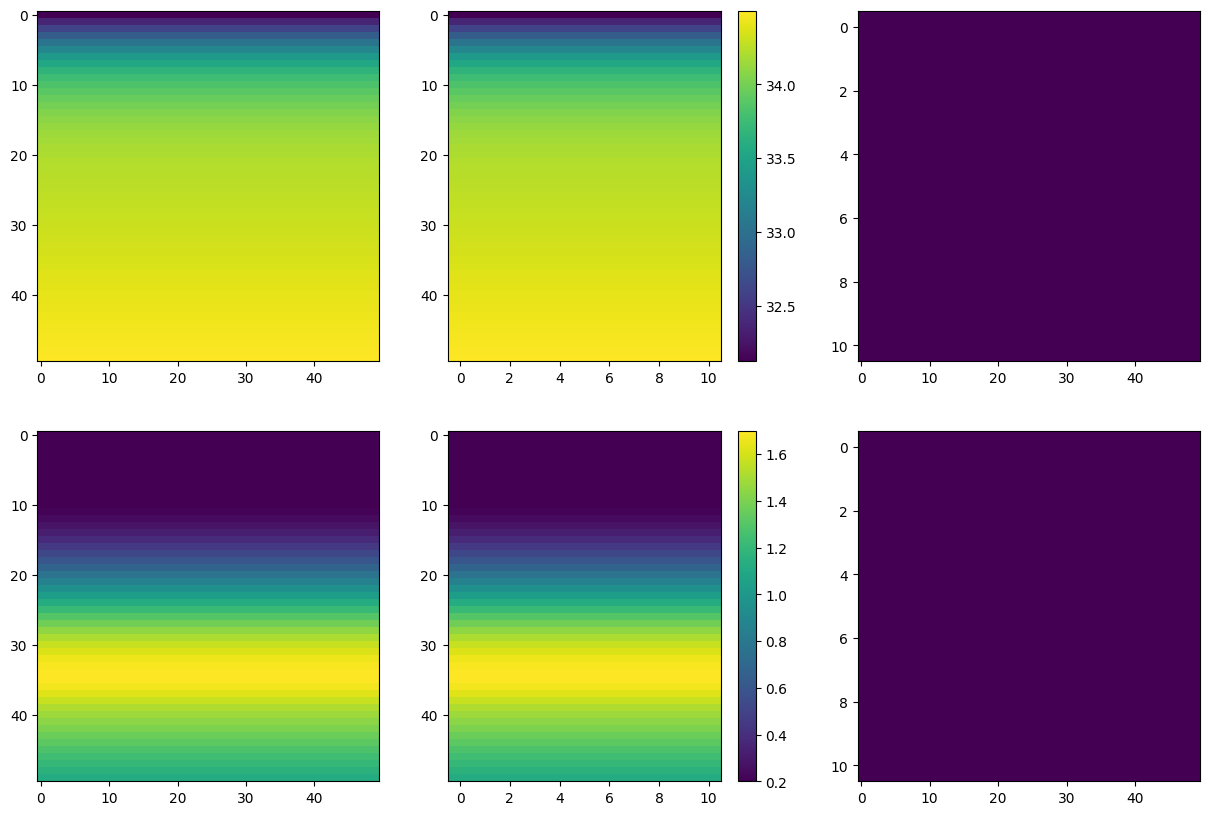

In [422]:
fig, ax = plt.subplots(2,3,figsize = (15,10))

ax[0,0].imshow(salt_ini[:,5,:].T, aspect = 'auto')
c = ax[0,1].imshow(salt_ini[25,:,:].T, aspect = 'auto')
plt.colorbar(c)
ax[0,2].imshow(salt_ini[:,:,0].T, aspect = 'auto')

ax[1,0].imshow(temp_ini[:,5,:].T, aspect = 'auto')
c = ax[1,1].imshow(temp_ini[25,:,:].T, aspect = 'auto')
plt.colorbar(c)
ax[1,2].imshow(temp_ini[:,:,0].T, aspect = 'auto')

In [ ]:
def write_plume_mask_tiled(mask_global, Nx, Ny, sNx, sNy, nSx, nSy, fname="plumeMask.bin"):
    """
    Convert a global Nx×Ny plume mask into MITgcm tiled binary format.

    Parameters
    ----------
    mask_global : ndarray, shape (Ny, Nx)
        Global 2D plume mask (row=Y, col=X).
    Nx, Ny : int
        Global domain size in X and Y.
    sNx, sNy : int
        Tile size in X and Y (interior, without overlap).
    nSx, nSy : int
        Number of tiles in X and Y.
    fname : str
        Output binary filename.
    """
    # Check consistency
    assert Nx == sNx * nSx, f"Nx mismatch: Nx={Nx}, but sNx*nSx={sNx*nSx}"
    assert Ny == sNy * nSy, f"Ny mismatch: Ny={Ny}, but sNy*nSy={sNy*nSy}"

    # Open binary for writing in big-endian 64-bit floats (MITgcm _RL default)
    with open(fname, "wb") as f:
        for bj in range(nSy):       # loop over tiles in Y
            for bi in range(nSx):   # loop over tiles in X
                i0 = bi * sNx
                i1 = i0 + sNx
                j0 = bj * sNy
                j1 = j0 + sNy

                # Extract tile from global
                tile = mask_global[j0:j1, i0:i1]

                # Write in Fortran order (column-major), _RL = float64
                tile.astype(">f8").tofile(f)

    print(f"Wrote plume mask to {fname} in tiled format.")

In [138]:
sNx, sNy = 50, 11
nSx, nSy = 1, 1
Nx, Ny = sNx * nSx, sNy* nSy


mask_global = np.zeros((Ny, Nx))
mask_global[:, 0] = 1
mask_global[int(Ny/2), 0] = 3

write_plume_mask_tiled(mask_global, Nx, Ny, sNx, sNy, nSx, nSy, fname="experiments/doubleplume_base/input/plumeMask.bin")


Wrote plume mask to experiments/doubleplume_base/input/plumeMask.bin in tiled format.
